# When and where should Citi Bike move its bikes?
DAO2702X group project: the analysis behind the report.

**Contents**

- Objective
- 1\. Data
    - 1.1 Raw files
    - 1.2 Parse and join
- 2\. Split
- 3\. Exploration
    - 3.1 Dataset checks
    - 3.2 The target
    - 3.3 Time of day
    - 3.4 Where bikes pile up and run out
    - 3.5 Does the imbalance recur?
    - 3.6 Drift against capacity
    - 3.7 Commuter corridors
    - 3.8 Season and weather
    - What the exploration found

## Objective

Every weekday morning, commuters ride from homes in Brooklyn, Queens and upper Manhattan to offices in Midtown and downtown, and ride back in the evening. The stations they leave run out of bikes and the stations they ride to run out of free docks, so the next rider finds no bike to take or nowhere to return one. Citi Bike moves bikes by truck, van and cargo bike, and pays riders through Bike Angels to ride against the flow. Every move costs money, so the question is which stations to restock or clear, by how many bikes, and at what time of day, to prevent the most shortages for the bikes moved.

Each row is one station in one hour.

| Quantity | Definition | Meaning |
|---|---|---|
| `starts` | trips that began at the station in the hour | bikes taken out |
| `ends` | trips that ended there in the hour | bikes brought in |
| `net_flow` | `ends - starts` | +5 means the station gained 5 bikes in the hour |
| `drift` | `net_flow` added up since the last restock | how far the stock has moved from the level the truck left |

A station runs short when its stock reaches 0, so the next rider finds no bike, or reaches its number of docks, so the next rider cannot return one. A schedule sets three things: which stations get a visit, the stock each is set to, and when the visits happen, overnight only or also between the rush hours. It is scored on held-out days by two numbers: the shortages left (riders arriving at an empty station plus riders returning to a full one) and the bikes moved.

The analysis runs in four steps, each answering the question the last one raises: describe when and where the flow runs one way; diagnose what makes it repeat (hour, weekday, place, rider type, weather); predict each station's hourly starts and ends for the next day; and prescribe, by simulating rebalancing schedules on those forecasts and counting the shortages each one prevents per bike moved. Its last step follows Raviv and Kolka (2013), who set a station's overnight stock to the level that minimises its expected shortages over the next day, given its hourly rates of starts and ends. O'Mahony and Shmoys (2015) built Citi Bike's own overnight and mid-rush rebalancing tools on the same idea.

Two limits shape every number. The files record completed trips, so a rider who found a station empty and walked away leaves no trace, and demand at stations that often run empty is undercounted. And the files hold no stock levels and none of the bikes Citi Bike moved itself, so stock is rebuilt from the flows, starting from an assumed level.

Import the libraries and the project's own tools, and set the shared chart style.

In [1]:
import os

# Polars takes every core by default; six of the ten leave the machine usable while the notebook runs.
# This has to be set before polars is imported.
os.environ["POLARS_MAX_THREADS"] = "6"

from datetime import date, datetime
from itertools import pairwise
from pathlib import Path

import polars as pl
from plotnine import (
    aes,
    coord_fixed,
    element_blank,
    element_text,
    facet_wrap,
    geom_abline,
    geom_histogram,
    geom_line,
    geom_point,
    geom_segment,
    geom_tile,
    geom_vline,
    ggplot,
    labs,
    scale_color_gradient2,
    scale_color_manual,
    scale_fill_gradient2,
    scale_size,
    scale_x_continuous,
    theme,
    theme_minimal,
    theme_set,
)

from lib.data_schemas import Station, StationHour
from lib.fetching import fetch_station_capacity, fetch_trip_month, fetch_weather

RAW = Path("data/raw")

# one palette for every chart: blue is the commuter side (weekdays, members, stations gaining bikes),
# orange the leisure side (weekends, casual riders), grey is context, red marks stations losing bikes
BLUE = "#2a78d6"
ORANGE = "#eb6834"
CONTEXT = "#b4b2ab"
LOSING_RED = "#e34948"
NEUTRAL = "#f0efec"

# legend on top: a legend on the right sits past the pane edge when the plot is wide
theme_set(
    theme_minimal()
    + theme(
        figure_size=(10, 4.5),
        legend_position="top",
        plot_title=element_text(size=12, weight="bold"),
        text=element_text(color="#0b0b0b"),
    )
)
# a kernel has no terminal, so polars would squeeze every table into ~100 characters
_ = (
    pl.Config.set_tbl_rows(30)
    .set_tbl_cols(-1)  # show every column
    .set_tbl_width_chars(1000)  # wide tables use the pane instead of wrapping
    .set_fmt_str_lengths(60)
    .set_float_precision(3)
)

## 1. Data

### 1.1 Raw files

| File | Rows | What it gives this project |
|---|---|---|
| `tripdata.nosync/YYYYMM-citibike-tripdata.parquet` | one per trip, 24 months | Citi Bike's public trip records, October 2024 to September 2026: start and end time, start and end station, bike type, member or casual rider. Each file holds one S3 zip, renamed `.parquet` |
| `station_information-2026-10-22.json` | 2,519 stations | Citi Bike's live station feed: each station's number of docks |
| `weather-central-park-20241001-20260930.csv` | 17,520 hours | Open-Meteo's hourly archive for Central Park: temperature and precipitation |

The trip files are the system's own record of every ride. They hold no stock levels and no record of the bikes Citi Bike moves itself, so how full a station is has to be rebuilt from the trips, and the number of docks from the live feed. The `.nosync` ending keeps iCloud from uploading the 2.6 GB of trips.

Tools from `lib/`:

| Tool | Goes in | Does | Comes out |
|---|---|---|---|
| `fetch_trip_month(month, folder)` | a month, the trip folder | downloads that month's zip from Citi Bike's S3 bucket and saves it as Parquet, unless the file is already there | the file's path |
| `fetch_station_capacity(folder)` | the raw folder | pulls the live station feed once and keeps it | station id, docks, feed name |
| `fetch_weather(start, end, folder)` | first and last day | pulls Central Park's hourly weather once and keeps it | hour, temperature, precipitation, snowfall, wind |
| `Station`, `StationHour` | a table | the data model: checks types, ranges and keys, and drops columns it does not list | the same table, validated |

Fetch every month from October 2024 to September 2026, or find it already saved.

In [2]:
FIRST_MONTH, LAST_MONTH = date(2024, 10, 1), date(2026, 9, 1)

months = pl.date_range(FIRST_MONTH, LAST_MONTH, "1mo", eager=True).to_list()
trip_files = [fetch_trip_month(month, RAW / "tripdata.nosync") for month in months]
pl.scan_parquet(trip_files).collect_schema()

Schema([('ride_id', String),
        ('rideable_type', String),
        ('started_at', Datetime(time_unit='us', time_zone=None)),
        ('ended_at', Datetime(time_unit='us', time_zone=None)),
        ('start_station_name', String),
        ('start_station_id', String),
        ('end_station_name', String),
        ('end_station_id', String),
        ('start_lat', Float64),
        ('start_lng', Float64),
        ('end_lat', Float64),
        ('end_lng', Float64),
        ('member_casual', String)])

### 1.2 Parse and join

Fixes made while reading, none of which depend on the values:

- station ids are kept as text, since `7293.10` read as a number becomes 7293.1 and no longer matches the feed
- some months still write ids with one decimal (`5980.1`); 95 of the 98 such ids have a twin with two decimals and the same name, so a one-decimal id gets its trailing zero back
- five stations also appear under a temporary id ending in `_` or `_old` (`5303.06_`), each with the same name as its usual id, so the ending is dropped
- a public dock has an id like `5303.06` in New York, or `JC` or `HB` plus digits in Jersey City and Hoboken; every other id is one of Citi Bike's own sites (the Morgan Ave depot's mechanics, loading docks and charging hub `1234.56`, the Bronx warehouse, a lab, three Los Angeles demo units), and a trip to or from one counts only at its other end
- each file holds the trips that ended in its month. April 2026's file also repeats the 512 trips that began on 30 April and ended in May, which May's file holds as well, so a trip is kept only from the file of the month it ended. The trips that began on 31 March 2026 and ended in April are in neither file
- timestamps are read to the second in New York local time, the clock the files are written in; some months carry milliseconds and some do not
- a trip counts as a start at its start station in the hour it began, and as an end at its end station in the hour it ended
- a trip with no start or no end station (an e-bike left outside a dock) counts only on the side that has one
- every station gets a row for every hour from its first trip to its last, with zeros for hours without trips, so averages over hours count the quiet ones
- the weather archive lists 01:00 twice on the night the clocks go back; the two readings are averaged so each hour appears once
- a station's docks come from the feed by id, or by name when the id is not in the feed and exactly one feed station has that name, since renumbered stations keep their name
- 35 feed stations list 0 docks, which on the day of the pull means out of service rather than a station without docks, so their capacity counts as unknown

Read the 24 trip files lazily, keep each trip from the file of the month it ended, and apply the station-id fixes to both ends of every trip. Ids are stored as categories, one small integer per row standing for the text, since the station-hour table repeats each id about 17,000 times.

In [3]:
# the depot's charging hub has an id shaped like a public dock's
CHARGING_HUB = "1234.56"


def public_station_id(column: str) -> pl.Expr:
    """The station's usual id, or null when the id belongs to one of Citi Bike's own sites."""
    station_id = pl.col(column).str.replace(r"_(old)?$", "")
    station_id = (
        pl.when(station_id.str.contains(r"^\d+\.\d$"))
        .then(station_id + "0")
        .otherwise(station_id)
    )
    is_public = station_id.str.contains(r"^(\d+\.\d{2}|JC\d+|HB\d+)$") & (
        station_id != CHARGING_HUB
    )
    return pl.when(is_public).then(station_id).cast(pl.Categorical)


trips = (
    pl.scan_parquet(trip_files, include_file_paths="file")
    .filter(
        pl.col("file").str.extract(r"(\d{6})-citibike")
        == pl.col("ended_at").dt.strftime("%Y%m")
    )
    .drop("file")
    .with_columns(
        start_station_id=public_station_id("start_station_id"),
        end_station_id=public_station_id("end_station_id"),
    )
)

Count, one month at a time, the starts at every station in every hour (with how many were by members and how many on e-bikes) and the ends, and put them side by side: one row per station and hour with any trip. A month's starts are the trips that began in it and its ends the trips that ended in it, so no station-hour falls in two months. Going month by month keeps one month of groups in memory instead of two years'.

In [4]:
month_starts = pl.datetime_range(
    datetime(2024, 10, 1), datetime(2026, 10, 1), "1mo", eager=True
).to_list()

monthly_counts: list[pl.DataFrame] = []
for month_start, next_month_start in pairwise(month_starts):
    starts = (
        trips.filter(
            pl.col("started_at").is_between(
                month_start, next_month_start, closed="left"
            )
        )
        .drop_nulls("start_station_id")
        .group_by(
            station_id="start_station_id", hour=pl.col("started_at").dt.truncate("1h")
        )
        .agg(
            pl.len().alias("starts"),
            (pl.col("member_casual") == "member").sum().alias("member_starts"),
            (pl.col("rideable_type") == "electric_bike").sum().alias("ebike_starts"),
        )
    )
    ends = (
        trips.filter(
            pl.col("ended_at").is_between(month_start, next_month_start, closed="left")
        )
        .drop_nulls("end_station_id")
        .group_by(
            station_id="end_station_id", hour=pl.col("ended_at").dt.truncate("1h")
        )
        .agg(pl.len().alias("ends"))
    )
    monthly_counts.append(
        starts.join(ends, on=["station_id", "hour"], how="full", coalesce=True)
        # counts come out unsigned, and ends - starts would wrap around instead of going negative
        .with_columns(
            pl.col("starts", "member_starts", "ebike_starts", "ends")
            .fill_null(0)
            .cast(pl.Int32)
        )
        .collect(engine="streaming")
    )
sum(counts.height for counts in monthly_counts)

23719341

Read the hourly weather, averaging the doubled hour on the night the clocks go back.

In [5]:
weather = (
    fetch_weather(date(2024, 10, 1), date(2026, 9, 30), RAW)
    .group_by("hour")
    .agg(pl.col("temperature_c", "precipitation_mm").mean().cast(pl.Float32))
)

Give every station a row for each hour from its first trip to its last, fill the empty hours with zeros, and add the net flow and the weather. This too runs one month at a time: each month's piece is every station open in it times the month's hours, about 1.7 million rows, and the 24 pieces stack in time order.

In [6]:
station_spans = (
    pl.concat(
        counts.group_by("station_id").agg(
            pl.col("hour").min().alias("first_hour"),
            pl.col("hour").max().alias("last_hour"),
        )
        for counts in monthly_counts
    )
    .group_by("station_id")
    .agg(pl.col("first_hour").min(), pl.col("last_hour").max())
)

grid_pieces: list[pl.DataFrame] = []
for (month_start, next_month_start), counts in zip(
    pairwise(month_starts), monthly_counts, strict=True
):
    month_hours = pl.datetime_range(
        month_start, next_month_start, "1h", closed="left", eager=True
    ).to_frame("hour")
    grid_pieces.append(
        station_spans.join(month_hours, how="cross")
        .filter(pl.col("hour").is_between(pl.col("first_hour"), pl.col("last_hour")))
        .drop("first_hour", "last_hour")
        .join(counts, on=["station_id", "hour"], how="left")
        .with_columns(
            pl.col("starts", "member_starts", "ebike_starts", "ends").fill_null(0)
        )
        .with_columns(net_flow=pl.col("ends") - pl.col("starts"))
        .join(weather, on="hour", how="left")
        .sort("station_id", "hour")
    )
del monthly_counts

Stack the pieces and check the result against the data model.

In [7]:
station_hours = StationHour.validate(pl.concat(grid_pieces))
del grid_pieces
station_hours.shape

(39573630, 9)

Build the station table: each station's most used name, its median coordinates over all trip ends, and its docks from the live feed, matched by id and then by name.

In [8]:
station_points = pl.concat(
    [
        trips.select(
            station_id="start_station_id",
            name="start_station_name",
            lat="start_lat",
            lng="start_lng",
        ),
        trips.select(
            station_id="end_station_id",
            name="end_station_name",
            lat="end_lat",
            lng="end_lng",
        ),
    ]
).drop_nulls("station_id")

stations = (
    station_points.group_by("station_id")
    .agg(
        pl.col("name").mode().first(),
        pl.col("lat").median(),
        pl.col("lng").median(),
    )
    .collect(engine="streaming")
)
feed = fetch_station_capacity(RAW).with_columns(
    capacity=pl.when(pl.col("capacity") > 0).then(pl.col("capacity"))
)
feed_by_name = feed.filter(pl.col("feed_name").is_unique()).select(
    name="feed_name", capacity_by_name="capacity"
)
stations = (
    stations.join(
        feed.select(pl.col("station_id").cast(pl.Categorical), "capacity"),
        on="station_id",
        how="left",
    )
    .join(feed_by_name, on="name", how="left")
    .with_columns(capacity=pl.coalesce("capacity", "capacity_by_name"))
)
stations = Station.validate(stations)
stations.shape

(2551, 5)

Count how many trips the files hold and how many reach the station-hour table on each side.

In [9]:
trip_counts = trips.select(
    pl.len().alias("trips"),
    pl.col("start_station_id").is_not_null().sum().alias("with_start_station"),
    pl.col("end_station_id").is_not_null().sum().alias("with_end_station"),
).collect(engine="streaming")
pl.DataFrame(
    {
        "step": [
            "trips in the 24 files",
            "counted as a start at a station",
            "counted as an end at a station",
            "starts in the station-hour table",
            "ends in the station-hour table",
        ],
        "trips": [
            trip_counts.item(0, "trips"),
            trip_counts.item(0, "with_start_station"),
            trip_counts.item(0, "with_end_station"),
            station_hours["starts"].sum(),
            station_hours["ends"].sum(),
        ],
    }
)

step,trips
str,i64
"""trips in the 24 files""",92085482
"""counted as a start at a station""",92024849
"""counted as an end at a station""",91800056
"""starts in the station-hour table""",92024337
"""ends in the station-hour table""",91800056


Of 92.1 million trips, 99.93% count as a start at a public station and 99.69% as an end; the rest began or ended at one of Citi Bike's own sites or outside a dock. The table holds 512 fewer starts than the files: trips that began on 30 September 2024, before the first hour of the table, and ended in October.

## 2. Split

Citi Bike always plans tomorrow's moves from the days before, so the split follows time. Two sets, each a full year, so that both cover every season:

- `dev`: October 2024 to September 2025, for exploration, building the forecast and choosing the schedule
- `test`: October 2025 to September 2026, the most recent full year, used once at the end to score the chosen schedule

From here on, everything that describes the values looks at `dev` only. `dev_trips` is the trip-level view of the same months, for the questions station-hours cannot answer, such as where each trip went.

In [10]:
TEST_START = datetime(2025, 10, 1)

dev = station_hours.filter(pl.col("hour") < TEST_START)
test = station_hours.filter(pl.col("hour") >= TEST_START)
dev_trips = trips.filter(pl.col("started_at") < TEST_START)

pl.DataFrame(
    {
        "set": ["dev", "test"],
        "station_hours": [dev.height, test.height],
        "stations": [dev["station_id"].n_unique(), test["station_id"].n_unique()],
        "first_hour": [frame["hour"].min() for frame in (dev, test)],
        "last_hour": [frame["hour"].max() for frame in (dev, test)],
    }
)

set,station_hours,stations,first_hour,last_hour
str,i64,i64,datetime[μs],datetime[μs]
"""dev""",19343824,2272,2024-10-01 00:00:00,2025-09-30 23:00:00
"""test""",20229806,2515,2025-10-01 00:00:00,2026-09-30 23:00:00


The two years meet at midnight on 1 October 2025 without overlap. `test` has 243 more stations than `dev`, because the network kept growing, and a station that opened in the test year has no history to plan from.

## 3. Exploration

### 3.1 Dataset checks

Checks of structure run on all 24 months: whether every day is there, whether a trip appears twice, and whether stations lack a dock count. Count the days with trips in each month and list the months with a day missing.

In [11]:
days_per_month = (
    trips.filter(pl.col("started_at") >= month_starts[0])
    .group_by(month=pl.col("started_at").dt.truncate("1mo"))
    .agg(pl.col("started_at").dt.date().n_unique().alias("days_with_trips"))
    .with_columns(days_in_month=pl.col("month").dt.month_end().dt.day())
    .with_columns(missing_days=pl.col("days_in_month") - pl.col("days_with_trips"))
    .sort("month")
    .collect(engine="streaming")
)
days_per_month.filter(pl.col("missing_days") != 0)

month,days_with_trips,days_in_month,missing_days
datetime[μs],u32,i8,i64
2026-02-01 00:00:00,27,28,1


Every day of the 24 months has trips except 23 February 2026, in the test year. Central Park had 22 cm of snow over 22 and 23 February, so the system was most likely shut for the storm. In the station-hour table that day counts as zero trips.

Count ride ids that appear more than once across the 24 files. The ids are compared by their 64-bit hash, which takes a fraction of the memory of 92 million text ids; the chance that two different ids share a hash anywhere in the files is about 1 in 4,000.

In [12]:
trips.select(
    pl.len().alias("trips"),
    pl.col("ride_id").hash().n_unique().alias("distinct_ride_ids"),
).collect(engine="streaming").with_columns(
    duplicated_ride_ids=pl.col("trips") - pl.col("distinct_ride_ids")
)

trips,distinct_ride_ids,duplicated_ride_ids
u32,u32,u32
92085482,92085482,0


No ride id appears twice once each trip is read only from the file of the month it ended.

Count how many stations lack a dock count in the live feed, and what share of `dev` trips start or end at them.

In [13]:
missing_capacity = stations.filter(pl.col("capacity").is_null())["station_id"]
pl.DataFrame(
    {
        "stations_without_capacity": [missing_capacity.len()],
        "stations": [stations.height],
        "dev_trip_ends_share": [
            dev.filter(pl.col("station_id").is_in(missing_capacity.implode()))
            .select(pl.col("starts").sum() + pl.col("ends").sum())
            .item()
            / dev.select(pl.col("starts").sum() + pl.col("ends").sum()).item()
        ],
    }
)

stations_without_capacity,stations,dev_trip_ends_share
i64,i64,f64
81,2551,0.041


81 of the 2,551 stations have no dock count, and they hold 4.1% of the trip ends in `dev`. They are the stations missing from the October 2026 feed, most likely closed or renumbered, plus the 35 listed as out of service. Anything measured against capacity covers the other 96% of trips.

Trip length is a value, so it is checked on `dev` only. Count the trips that end before they start, last under a minute, or last over a day.

In [14]:
dev_trips.select(
    duration_min=(pl.col("ended_at") - pl.col("started_at")).dt.total_seconds() / 60
).select(
    pl.len().alias("trips"),
    (pl.col("duration_min") < 0).sum().alias("negative"),
    (pl.col("duration_min").is_between(0, 1, closed="left"))
    .sum()
    .alias("under_a_minute"),
    (pl.col("duration_min") > 24 * 60).sum().alias("over_a_day"),
    pl.col("duration_min").median().alias("median_min"),
).collect(engine="streaming")

trips,negative,under_a_minute,over_a_day,median_min
u32,u32,u32,u32,f64
46702528,319,1,8992,8.867


319 trips in `dev` end before they start and 8,992 last over a day, together 0.02% of the 46.7 million; the median trip takes 8.9 minutes. That is too few to matter for hourly counts.

### 3.2 The target

Show how hourly net flow is spread across station-hours in `dev`: how often a station sees no trips, and how large the swings get.

In [15]:
dev.select(
    (pl.col("starts") + pl.col("ends") == 0).mean().alias("hours_without_trips_share"),
    (pl.col("net_flow") == 0).mean().alias("net_flow_zero_share"),
    pl.col("net_flow").quantile(0.01).alias("net_flow_p01"),
    pl.col("net_flow").quantile(0.99).alias("net_flow_p99"),
    pl.col("net_flow").min().alias("net_flow_min"),
    pl.col("net_flow").max().alias("net_flow_max"),
)

hours_without_trips_share,net_flow_zero_share,net_flow_p01,net_flow_p99,net_flow_min,net_flow_max
f64,f64,f64,f64,i32,i32
0.383,0.478,-9.000,9.000,-134,105


38% of station-hours in `dev` have no trip at all, and 48% have a net flow of exactly zero. 98% of hours move a station by 9 bikes or fewer either way, but the extremes reach a gain of 105 bikes in one hour and a loss of 134, more than the largest station's 123 docks. A station can only lose more bikes than it holds if staff refill it during the hour, so these are most likely stations with a valet service.

### 3.3 Time of day

Average the system-wide starts in each hour of the day, separately for weekdays and weekends, and for members and casual riders.

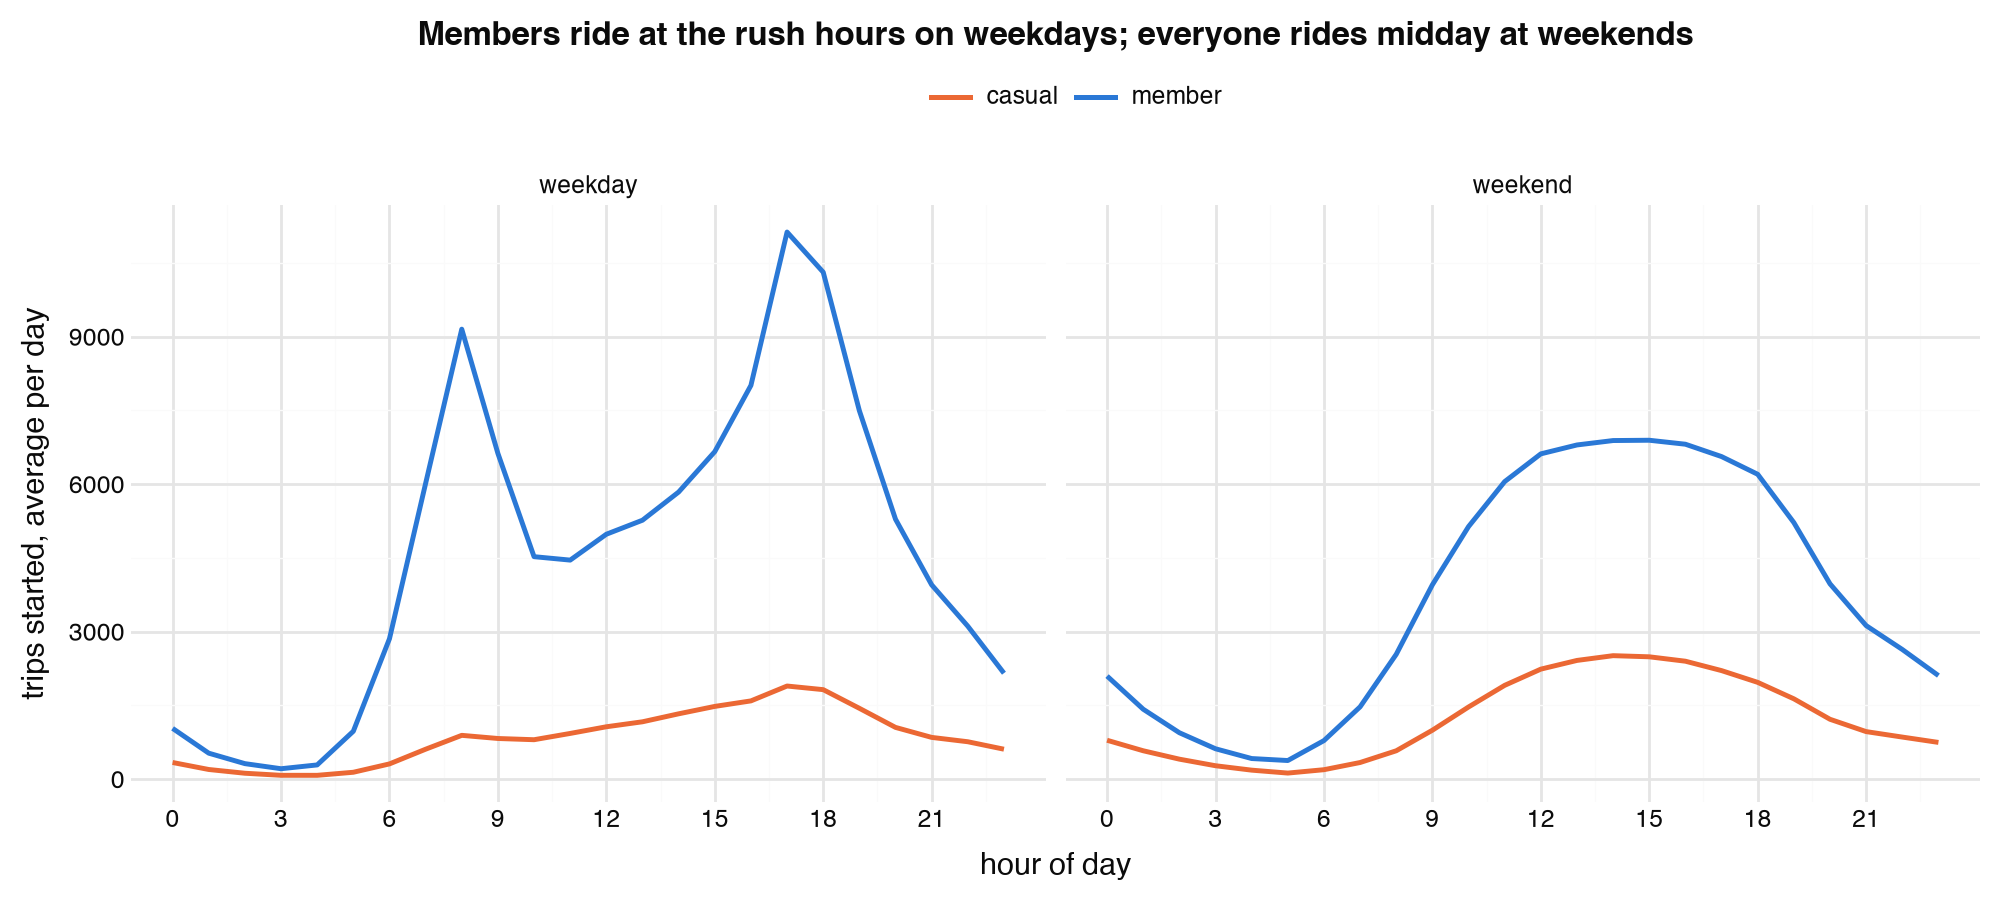

In [16]:
by_hour = (
    dev.with_columns(
        day_type=pl.when(pl.col("hour").dt.weekday() <= 5)
        .then(pl.lit("weekday"))
        .otherwise(pl.lit("weekend")),
        date=pl.col("hour").dt.date(),
        hour_of_day=pl.col("hour").dt.hour(),
    )
    .group_by("day_type", "date", "hour_of_day")
    .agg(
        member=pl.col("member_starts").sum(),
        casual=pl.col("starts").sum() - pl.col("member_starts").sum(),
    )
    .group_by("day_type", "hour_of_day")
    .agg(pl.col("member", "casual").mean())
    .unpivot(
        index=["day_type", "hour_of_day"], variable_name="rider", value_name="starts"
    )
)

(
    ggplot(by_hour, aes("hour_of_day", "starts", color="rider"))
    + geom_line(size=1)
    + facet_wrap("day_type")
    + scale_color_manual(values={"member": BLUE, "casual": ORANGE})
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        title="Members ride at the rush hours on weekdays; everyone rides midday at weekends",
        x="hour of day",
        y="trips started, average per day",
        color="",
    )
)

On weekdays, members start about 9,200 trips in the 08:00 hour and 11,200 in the 17:00 hour, against about 4,500 at 11:00, while casual riders barely change through the day. At weekends both groups follow one curve that peaks at 14:00 to 15:00. The one-way flow comes from weekday members, so weekdays and weekends need separate plans.

### 3.4 Where bikes pile up and run out

On weekdays, average each station's net flow over the morning rush (07:00 to 10:00) and the evening rush (16:00 to 19:00). `rush_net_flow` is the bikes a station gains, or loses when negative, over the three hours of one rush, averaged over `dev` weekdays.

In [17]:
rush = (
    dev.filter(pl.col("hour").dt.weekday() <= 5)
    .with_columns(
        rush=pl.when(pl.col("hour").dt.hour().is_between(7, 9))
        .then(pl.lit("morning rush, 07-10"))
        .when(pl.col("hour").dt.hour().is_between(16, 18))
        .then(pl.lit("evening rush, 16-19"))
        # morning first in every table and panel
        .cast(pl.Enum(["morning rush, 07-10", "evening rush, 16-19"]))
    )
    .drop_nulls("rush")
    .group_by("station_id", "rush", date=pl.col("hour").dt.date())
    .agg(pl.col("net_flow").sum())
    .group_by("station_id", "rush")
    .agg(pl.col("net_flow").mean().alias("rush_net_flow"))
    .join(stations, on="station_id")
)
rush.group_by("rush").agg(
    (pl.col("rush_net_flow") <= -5).sum().alias("stations_losing_5_plus"),
    (pl.col("rush_net_flow") >= 5).sum().alias("stations_gaining_5_plus"),
    pl.col("rush_net_flow").min().alias("largest_loss"),
    pl.col("rush_net_flow").max().alias("largest_gain"),
).sort("rush")

rush,stations_losing_5_plus,stations_gaining_5_plus,largest_loss,largest_gain
enum,u32,u32,f64,f64
"""morning rush, 07-10""",402,289,-60.682,106.349
"""evening rush, 16-19""",221,252,-105.165,43.958


In the average weekday morning rush, 402 stations lose 5 bikes or more and 289 gain 5 or more, and the largest gain is 106 bikes. Fewer stations swing in the evening rush: 221 lose 5 or more and 252 gain 5 or more.

Map every station, coloured by its rush net flow; the scale stops at ±15 bikes so the many smaller stations still show their colour.

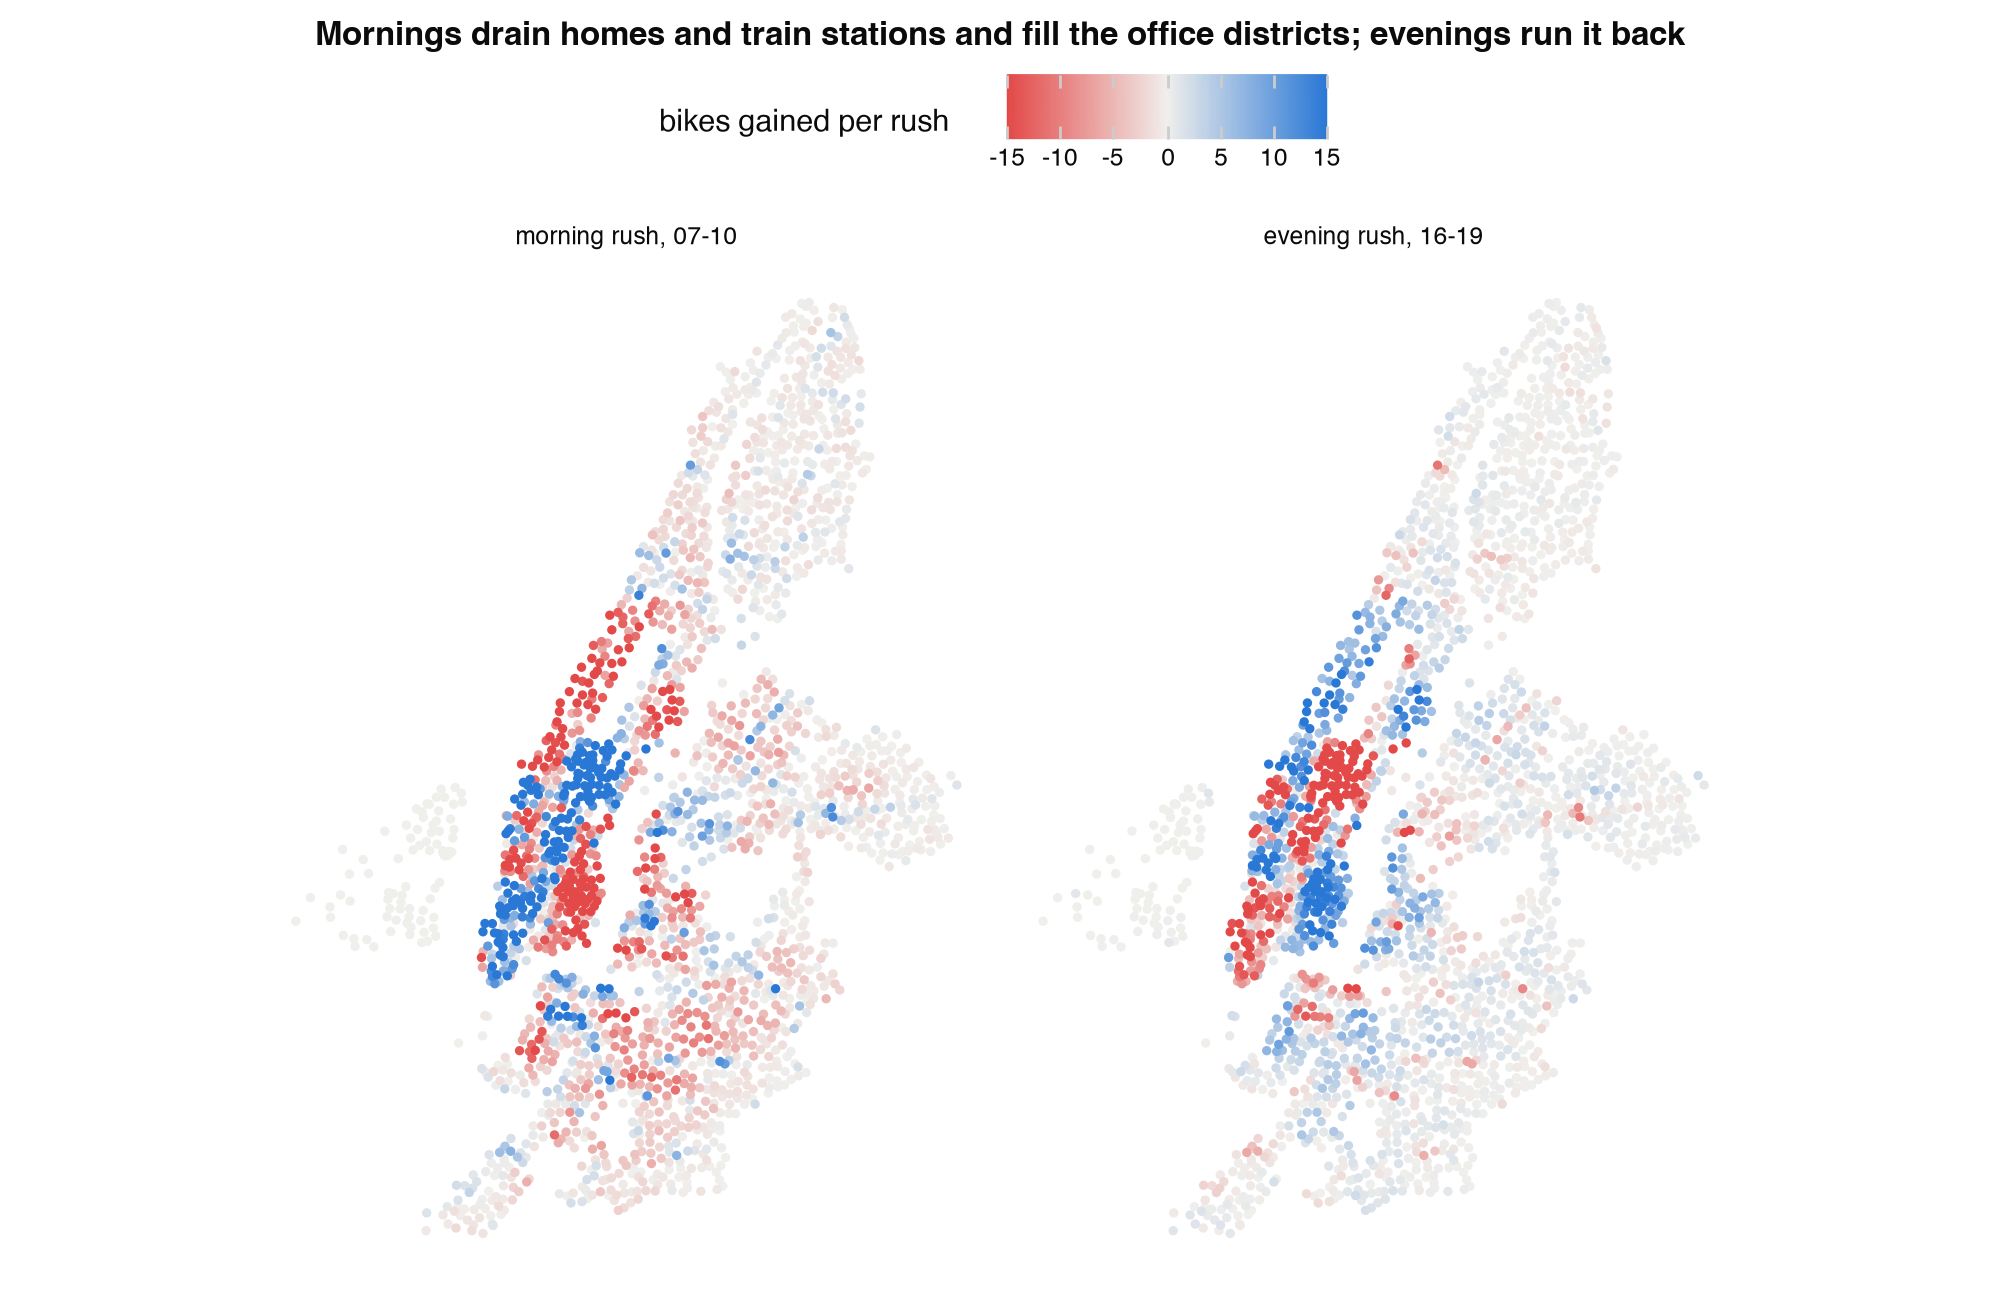

In [18]:
# one degree of longitude is shorter than one of latitude at New York's 40.7 degrees north
LNG_PER_LAT = 1 / 0.758
# coordinates carry no meaning for the reader, so maps drop the axes and the grid
MAP_THEME = theme(
    axis_text=element_blank(), axis_title=element_blank(), panel_grid=element_blank()
)

(
    ggplot(
        rush.with_columns(pl.col("rush_net_flow").clip(-15, 15)).sort(
            pl.col("rush_net_flow").abs()
        ),
        aes("lng", "lat", color="rush_net_flow"),
    )
    + geom_point(size=0.9)
    + facet_wrap("rush")
    + scale_color_gradient2(
        low=LOSING_RED, mid=NEUTRAL, high=BLUE, midpoint=0, limits=(-15, 15)
    )
    + coord_fixed(ratio=LNG_PER_LAT)
    + labs(
        title="Mornings drain the residential areas and fill the office districts; evenings run it back",
        color="bikes gained per rush",
    )
    + MAP_THEME
    + theme(figure_size=(10, 6.5))
)

In the morning, the residential Upper West and Upper East Sides and much of Brooklyn lose bikes, and the office districts of Midtown and Lower Manhattan gain them. In the evening the same areas swap colours. Stations in the Bronx, eastern Queens and Jersey City stay grey: they barely change either way.

### 3.5 Does the imbalance recur?

A schedule built on past days only helps if a station's imbalance repeats. Split the `dev` weekdays into odd and even ISO weeks, average each station's morning-rush net flow in each half, and compare the two. If the pattern is a habit, a station's two averages land close to the diagonal. The rank correlation compares the stations' order instead of their values, so the few stations with swings near 100 bikes cannot carry it alone.

In [19]:
morning = (
    dev.filter(
        (pl.col("hour").dt.weekday() <= 5) & pl.col("hour").dt.hour().is_between(7, 9)
    )
    .group_by(
        "station_id",
        date=pl.col("hour").dt.date(),
        half=pl.when(pl.col("hour").dt.week() % 2 == 1)
        .then(pl.lit("odd_weeks"))
        .otherwise(pl.lit("even_weeks")),
    )
    .agg(pl.col("net_flow").sum())
    .group_by("station_id", "half")
    .agg(pl.col("net_flow").mean())
    .pivot("half", index="station_id", values="net_flow")
    .drop_nulls()
)
morning.select(
    pl.corr("odd_weeks", "even_weeks").alias("correlation"),
    pl.corr("odd_weeks", "even_weeks", method="spearman").alias("rank_correlation"),
)

correlation,rank_correlation
f64,f64
0.998,0.995


Plot each station's odd-week average against its even-week average.

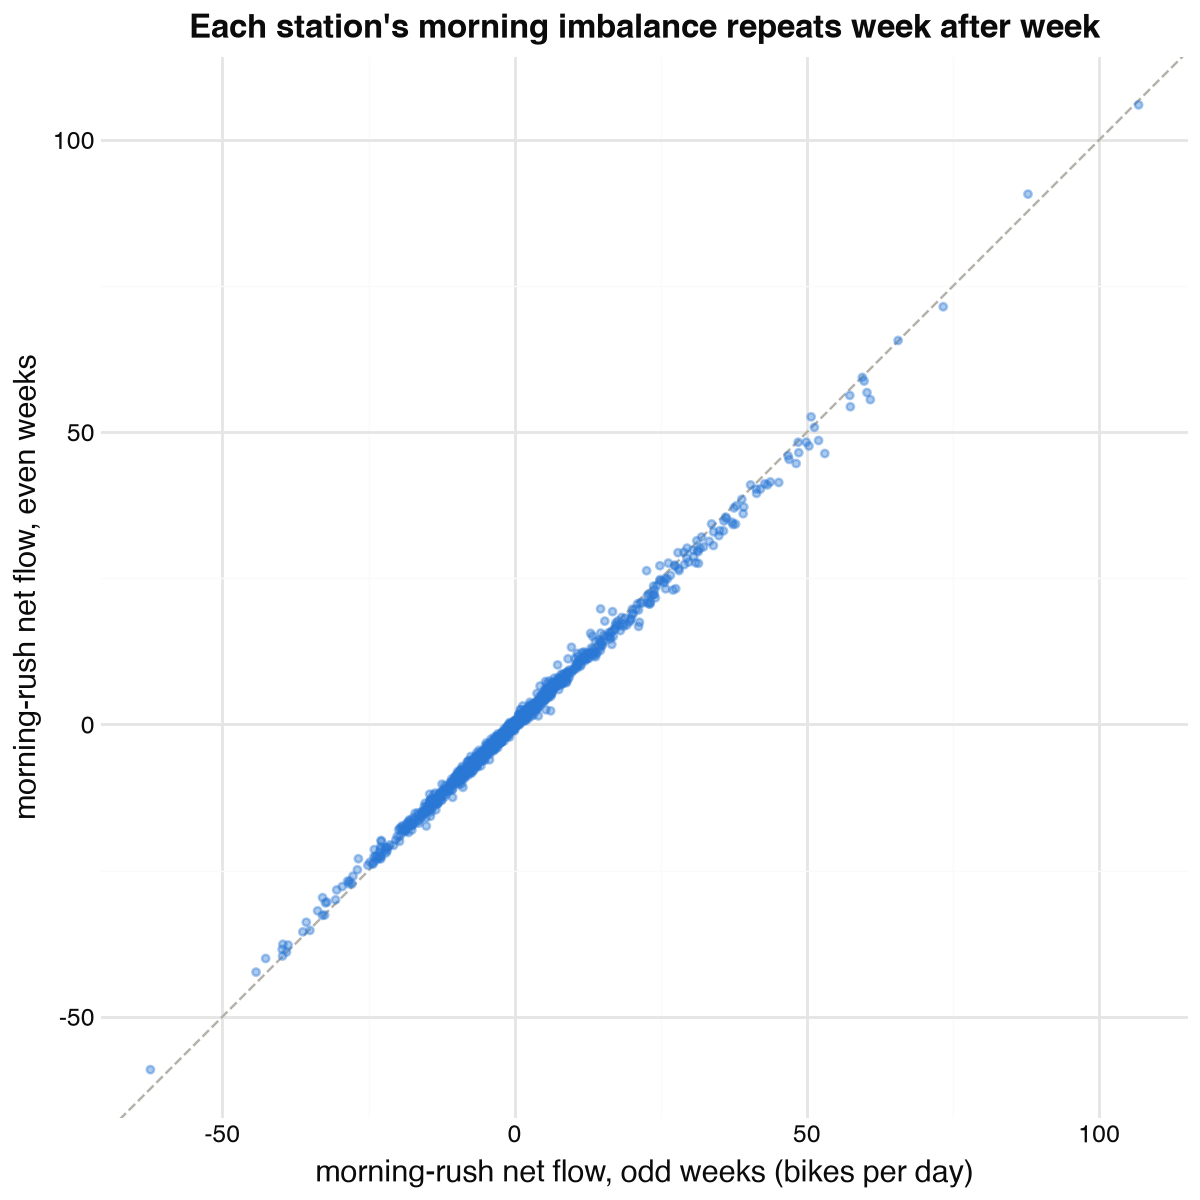

In [20]:
(
    ggplot(morning, aes("odd_weeks", "even_weeks"))
    + geom_abline(color=CONTEXT, linetype="dashed")
    + geom_point(color=BLUE, alpha=0.4, size=1)
    + coord_fixed()
    + labs(
        title="Each station's morning imbalance repeats week after week",
        x="morning-rush net flow, odd weeks (bikes per day)",
        y="morning-rush net flow, even weeks",
    )
    + theme(figure_size=(6, 6))
)

The correlation is 0.998 and the rank correlation 0.995: stations line up on the diagonal across the whole range, from losing 60 bikes a morning to gaining 106. Each half averages about 125 weekdays, so the day-to-day noise has averaged out. What repeats is each station's typical morning; how well a single day can be forecast is the question for the predictive step.

Show the 30 most imbalanced stations hour by hour: `mean_net_flow` is the station's average net flow in that hour over `dev` weekdays.

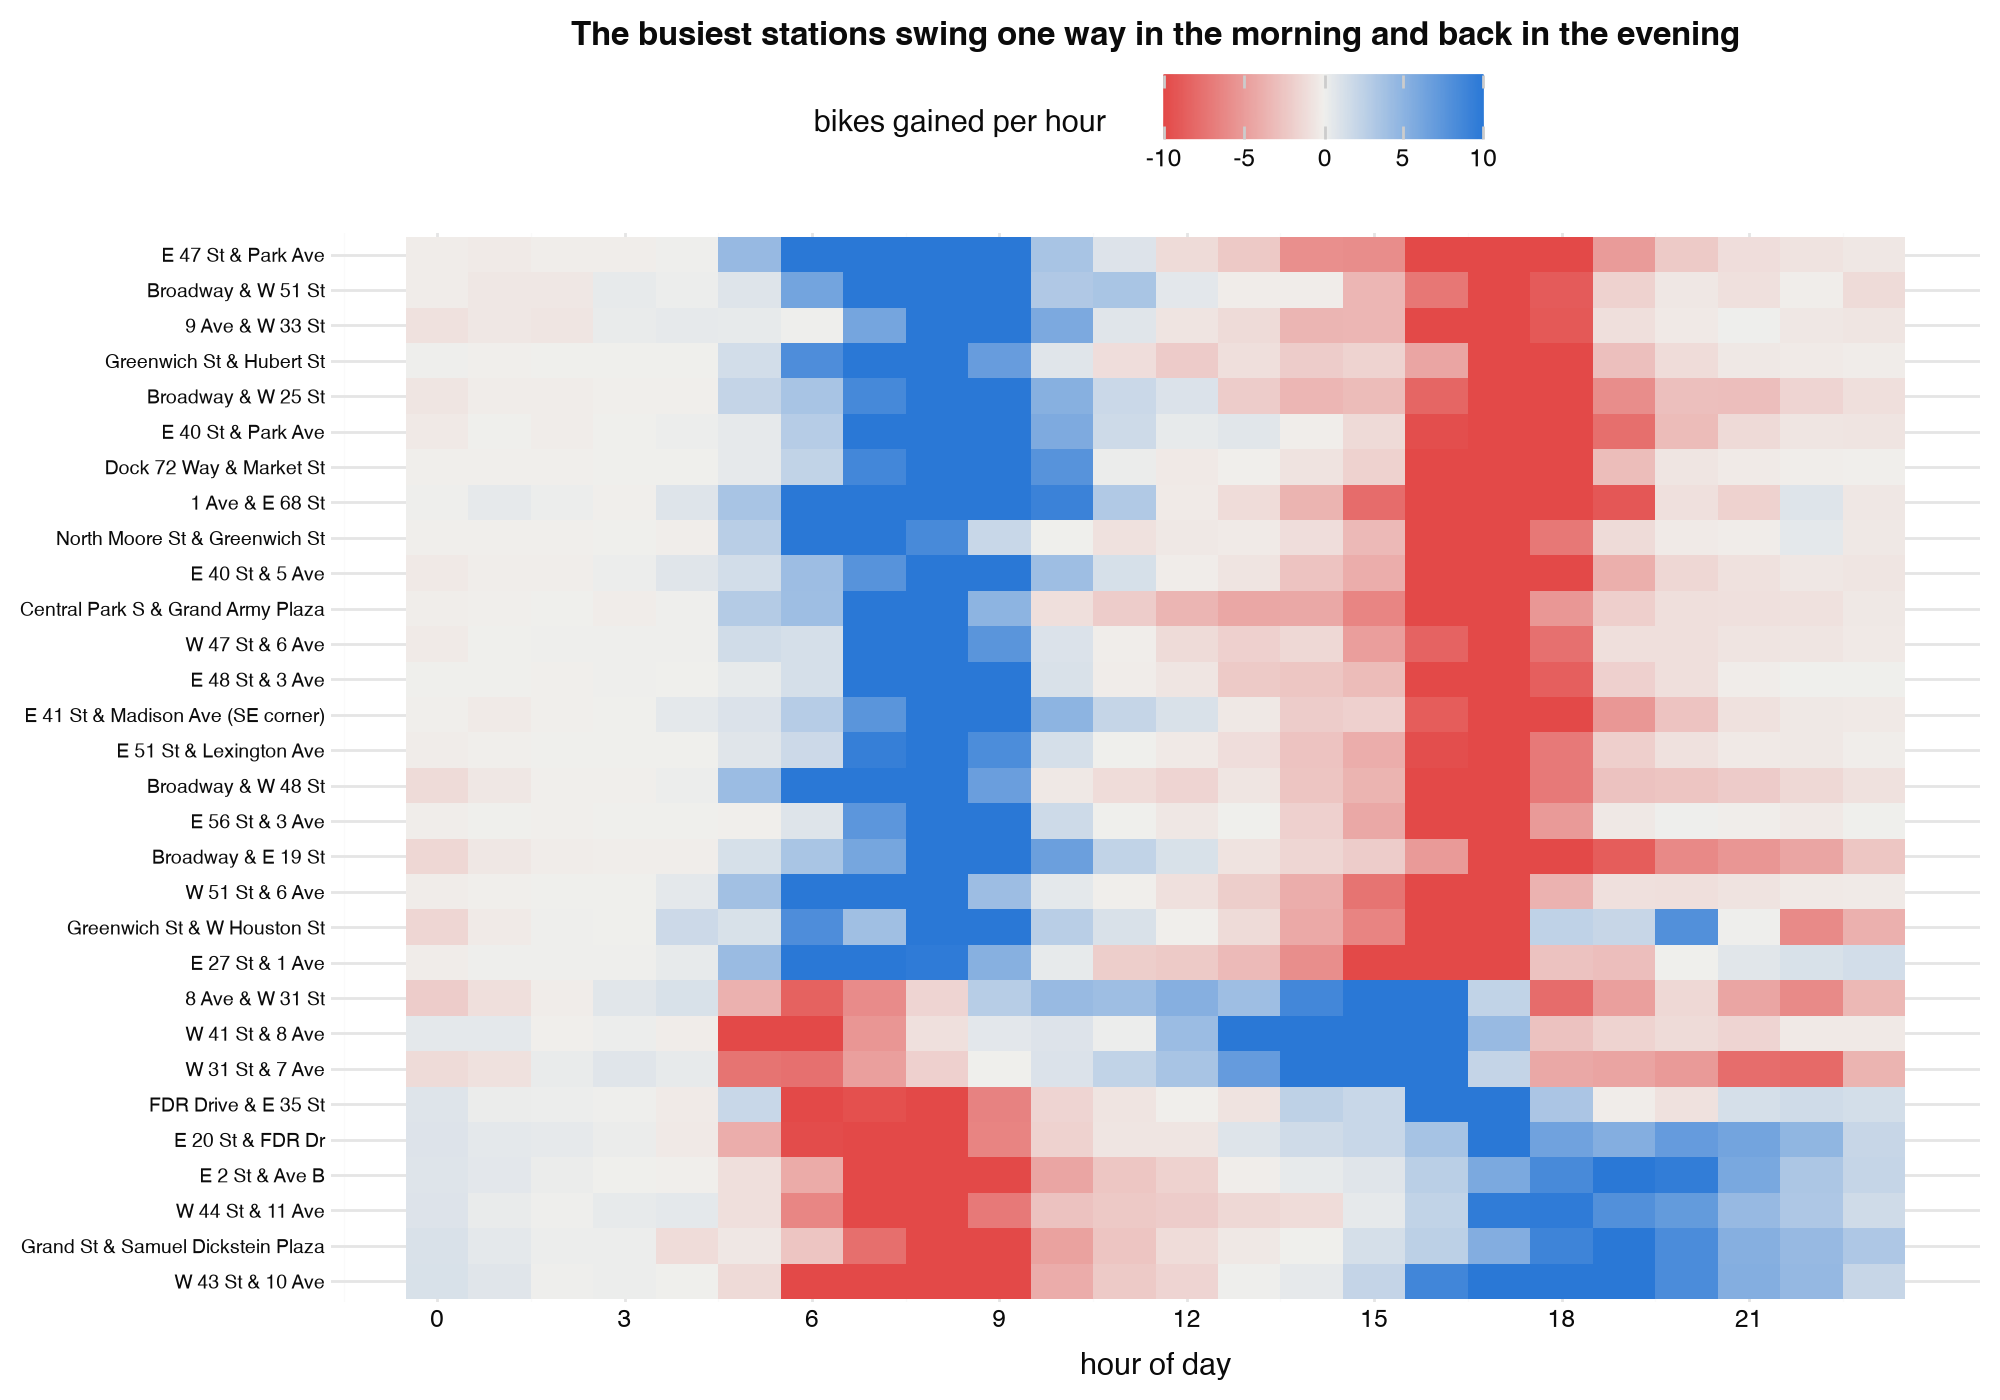

In [21]:
weekday_profile = (
    dev.filter(pl.col("hour").dt.weekday() <= 5)
    .group_by("station_id", hour_of_day=pl.col("hour").dt.hour())
    .agg(pl.col("net_flow").mean().alias("mean_net_flow"))
)
most_imbalanced = (
    weekday_profile.group_by("station_id")
    .agg(pl.col("mean_net_flow").abs().sum().alias("imbalance"))
    .top_k(30, by="imbalance")
)
# rows run from the station losing most in the morning rush to the one gaining most
row_order = (
    weekday_profile.filter(pl.col("hour_of_day").is_between(7, 9))
    .join(most_imbalanced, on="station_id")
    .group_by("station_id")
    .agg(pl.col("mean_net_flow").sum())
    .join(stations.select("station_id", "name"), on="station_id")
    .sort("mean_net_flow")
)
profile_top = weekday_profile.join(
    row_order.select("station_id", "name"), on="station_id"
).with_columns(
    pl.col("name").cast(pl.Enum(row_order["name"].unique(maintain_order=True)))
)

(
    ggplot(
        profile_top.with_columns(pl.col("mean_net_flow").clip(-10, 10)),
        aes("hour_of_day", "name", fill="mean_net_flow"),
    )
    + geom_tile()
    + scale_fill_gradient2(
        low=LOSING_RED, mid=NEUTRAL, high=BLUE, midpoint=0, limits=(-10, 10)
    )
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        title="The busiest stations swing one way in the morning and back in the evening",
        x="hour of day",
        y="",
        fill="bikes gained per hour",
    )
    + theme(figure_size=(10, 7), axis_text_y=element_text(size=7))
)

The 30 stations with the largest weekday swings fall into three groups. 21 stations in the office districts, from E 47 St & Park Ave down to E 27 St & 1 Ave, gain bikes from about 06:00 to 10:00 and lose them from 15:00 to 19:00. Six residential stations near the rivers, such as W 43 St & 10 Ave and E 2 St & Ave B, do the opposite. Three stations around Penn Station and Port Authority keep their own clock: they lose bikes from 05:00 and fill back up from noon to 16:00, which fits train commuters who arrive early and return their bikes before the evening trains.

### 3.6 Drift against capacity

How far a station's stock moves in a day decides whether one overnight restock can carry it. Within each `dev` weekday, starting at 04:00, the quietest hour, add up the station's net flow hour by hour. `drift` after each hour is that running total: the bikes gained since 04:00. A station that starts the day with `stock` bikes runs empty when `stock + min(drift) < 0` and full when `stock + max(drift) > capacity`, so two questions follow:

- `short_from_half_full_share`: the share of station-days on which a station that starts half full runs empty or full at some hour, `max(drift) > capacity / 2` or `min(drift) < -capacity / 2`. This is a station left alone after a plain overnight reset to half.
- `short_from_any_start_share`: the share on which no starting level works, because the day's swing `drift_range = max(drift, 0) - min(drift, 0)` is larger than the station's docks. Only bikes moved during the day help on those days.

`range_share = drift_range / capacity` is the swing in docks. Hourly totals hide swings inside an hour, and riders who found a station empty are missing, so both shares are lower bounds.

In [22]:
service_day = (pl.col("hour") - pl.duration(hours=4)).dt.date()

drift = (
    dev.filter(service_day.dt.weekday() <= 5)
    .with_columns(service_day=service_day)
    .with_columns(drift=pl.col("net_flow").cum_sum().over("station_id", "service_day"))
    .group_by("station_id", "service_day")
    .agg(
        pl.col("drift").max().clip(lower_bound=0).alias("drift_max"),
        pl.col("drift").min().clip(upper_bound=0).alias("drift_min"),
    )
    .with_columns(drift_range=pl.col("drift_max") - pl.col("drift_min"))
    .join(stations.select("station_id", "capacity"), on="station_id")
    .drop_nulls("capacity")
    .with_columns(range_share=pl.col("drift_range") / pl.col("capacity"))
)
drift.select(
    pl.len().alias("station_days"),
    (
        (pl.col("drift_max") > pl.col("capacity") / 2)
        | (pl.col("drift_min") < -pl.col("capacity") / 2)
    )
    .mean()
    .alias("short_from_half_full_share"),
    (pl.col("range_share") > 1).mean().alias("short_from_any_start_share"),
    pl.col("range_share").median().alias("median_range_share"),
    pl.col("range_share").quantile(0.95).alias("p95_range_share"),
)

station_days,short_from_half_full_share,short_from_any_start_share,median_range_share,p95_range_share
u32,f64,f64,f64,f64
561281,0.205,0.011,0.310,0.914


On 20.5% of weekday station-days in `dev`, a station that starts half full runs empty or full at some hour; on 1.1%, no starting level would have worked. The typical swing is 31% of a station's docks, and on 5% of station-days it reaches 91% or more. On the 19.4% of station-days in between, some starting level would have carried the station through the day, so 95% of the short days from a half-full start could have been avoided by a better overnight level, without moving bikes during the day. How close a forecast gets to choosing that level in advance is the question for the predictive step.

Take each station's median weekday swing in docks and plot how many stations sit at each level; the axis stops at 1.5, and the stations beyond it are listed below the chart.

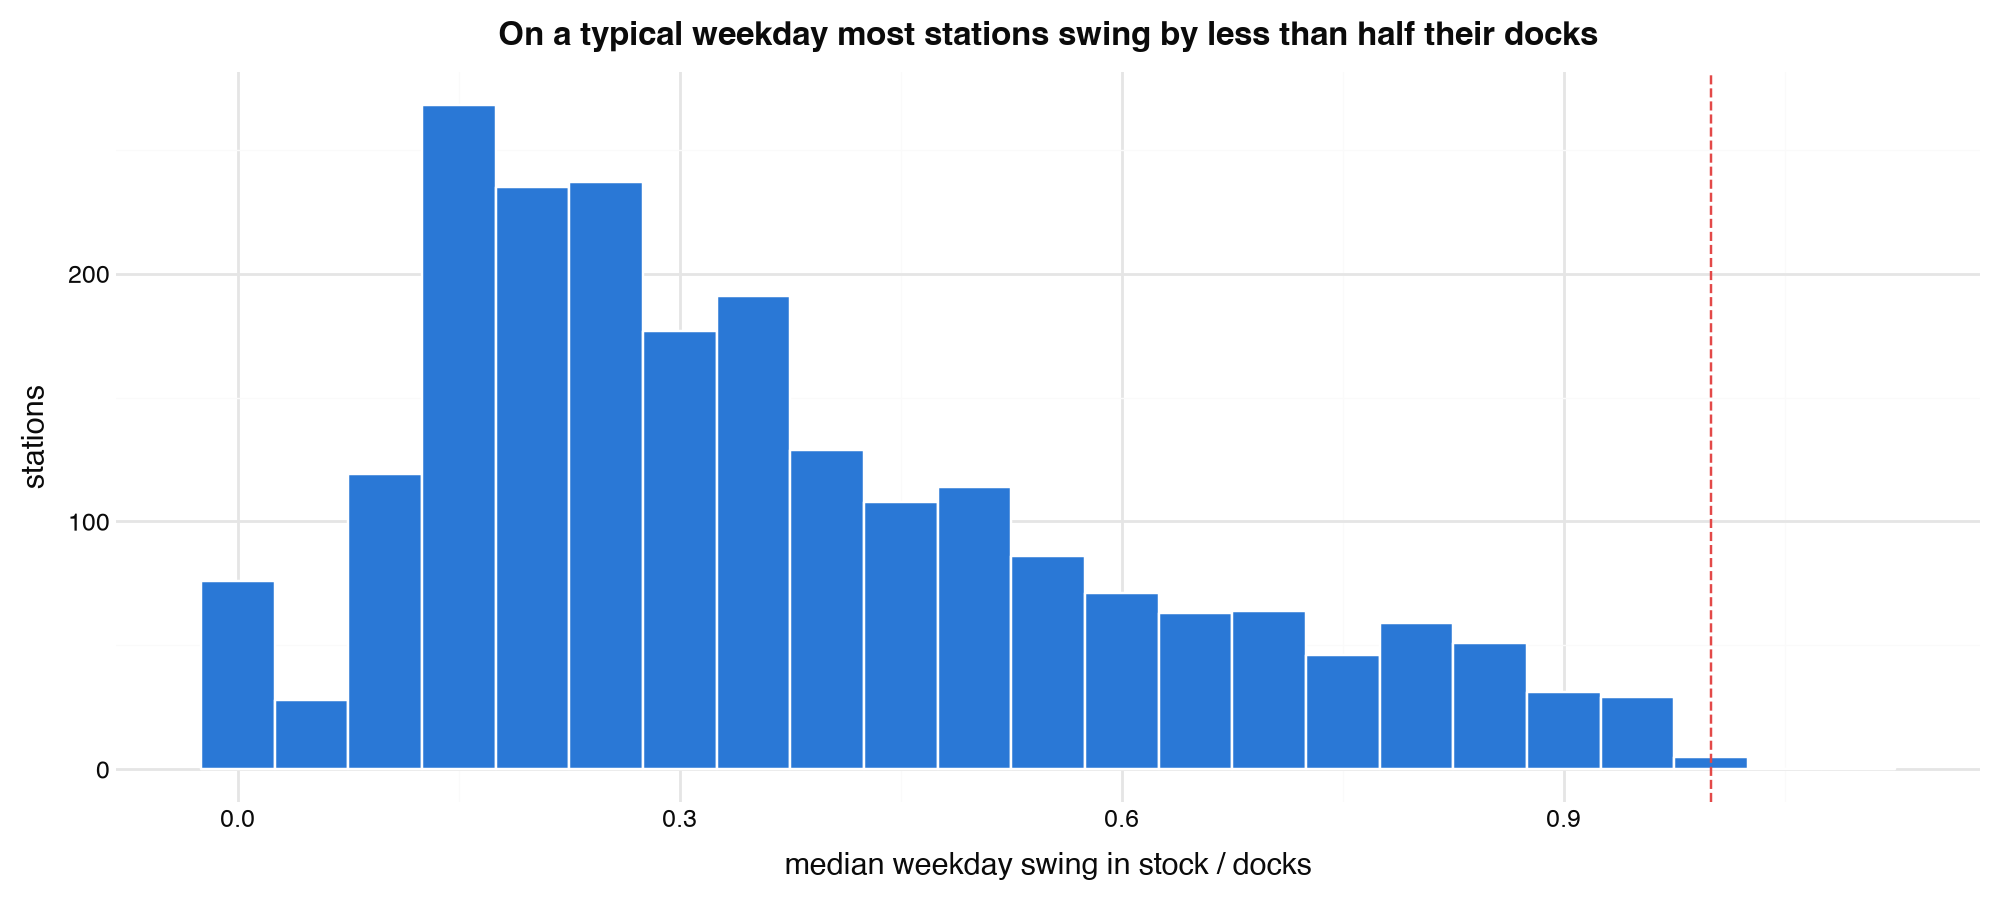

In [23]:
by_station_drift = drift.group_by("station_id", "capacity").agg(
    (pl.col("range_share") > 1).mean().alias("days_over_capacity_share"),
    pl.col("range_share").median().alias("median_range_share"),
)

(
    ggplot(
        by_station_drift.filter(pl.col("median_range_share") <= 1.5),
        aes("median_range_share"),
    )
    + geom_histogram(binwidth=0.05, fill=BLUE, color="white")
    + geom_vline(xintercept=1, color=LOSING_RED, linetype="dashed")
    + labs(
        title="On a typical weekday most stations swing by less than half their docks",
        x="median weekday swing in stock / docks",
        y="stations",
    )
)

Most stations' median swing sits between 10% and 50% of their docks, with a tail up to 100%.

List the stations whose typical weekday swing is larger than their docks.

In [24]:
by_station_drift.filter(pl.col("median_range_share") > 1).join(
    stations.select("station_id", "name"), on="station_id"
).sort("median_range_share", descending=True)

station_id,capacity,days_over_capacity_share,median_range_share,name
cat,i64,f64,f64,str
"""5470.12""",29,0.939,4.172,"""North Moore St & Greenwich St"""
"""4804.02""",22,0.927,3.545,"""Dock 72 Way & Market St"""
"""5470.10""",35,0.763,2.443,"""Greenwich St & Hubert St"""
"""6822.09""",63,0.927,1.857,"""1 Ave & E 68 St"""
"""6584.12""",81,0.866,1.827,"""E 47 St & Park Ave"""
"""6809.09""",43,0.740,1.651,"""W 55 St & 6 Ave"""
"""5365.02""",18,0.924,1.611,"""Columbia St & Rivington St"""
"""7409.04""",35,0.592,1.114,"""W 84 St & Amsterdam Ave"""
"""5922.07""",35,0.500,1.014,"""Perry St & Bleecker St"""


Nine stations swing by more than their docks on a typical weekday, and on 50% to 94% of all weekdays. Five of them are also among the 30 most imbalanced stations in the heatmap in 3.5: North Moore St & Greenwich St, Dock 72 Way & Market St, Greenwich St & Hubert St, 1 Ave & E 68 St and E 47 St & Park Ave. These few stations need bikes moved during the day as a rule, and they are few enough to name in a schedule.

### 3.7 Commuter corridors

Count the weekday morning-rush trips in `dev` for every pair of different stations, and keep the 300 busiest pairs.

In [25]:
morning_rush_trips = dev_trips.filter(
    (pl.col("started_at").dt.weekday() <= 5)
    & pl.col("started_at").dt.hour().is_between(7, 9)
    & (pl.col("start_station_id") != pl.col("end_station_id"))
)
coordinates = stations.select("station_id", "lat", "lng")
corridors = (
    morning_rush_trips.group_by("start_station_id", "end_station_id")
    .agg(pl.len().alias("trips"))
    .top_k(300, by="trips")
    .collect(engine="streaming")
    .join(coordinates, left_on="start_station_id", right_on="station_id")
    .join(coordinates, left_on="end_station_id", right_on="station_id", suffix="_end")
)
weekdays_in_dev = (
    dev.filter(pl.col("hour").dt.weekday() <= 5)["hour"].dt.date().n_unique()
)
pl.DataFrame(
    {
        "busiest_route_trips_per_weekday": [
            corridors.select(pl.col("trips").max()).item() / weekdays_in_dev
        ],
        "top_300_routes_share_of_morning_trips": [
            corridors["trips"].sum()
            / morning_rush_trips.select(pl.len()).collect(engine="streaming").item()
        ],
    }
)

busiest_route_trips_per_weekday,top_300_routes_share_of_morning_trips
f64,f64
7.088,0.036


The busiest single route carries 7.1 trips per weekday morning, and the 300 busiest routes together carry 3.6% of morning-rush trips. A station empties through many routes with a trip or two each, so rebalancing has to work station by station; no short list of routes explains the flow.

Draw each of the 300 routes as a line from start to end, thicker for more trips.

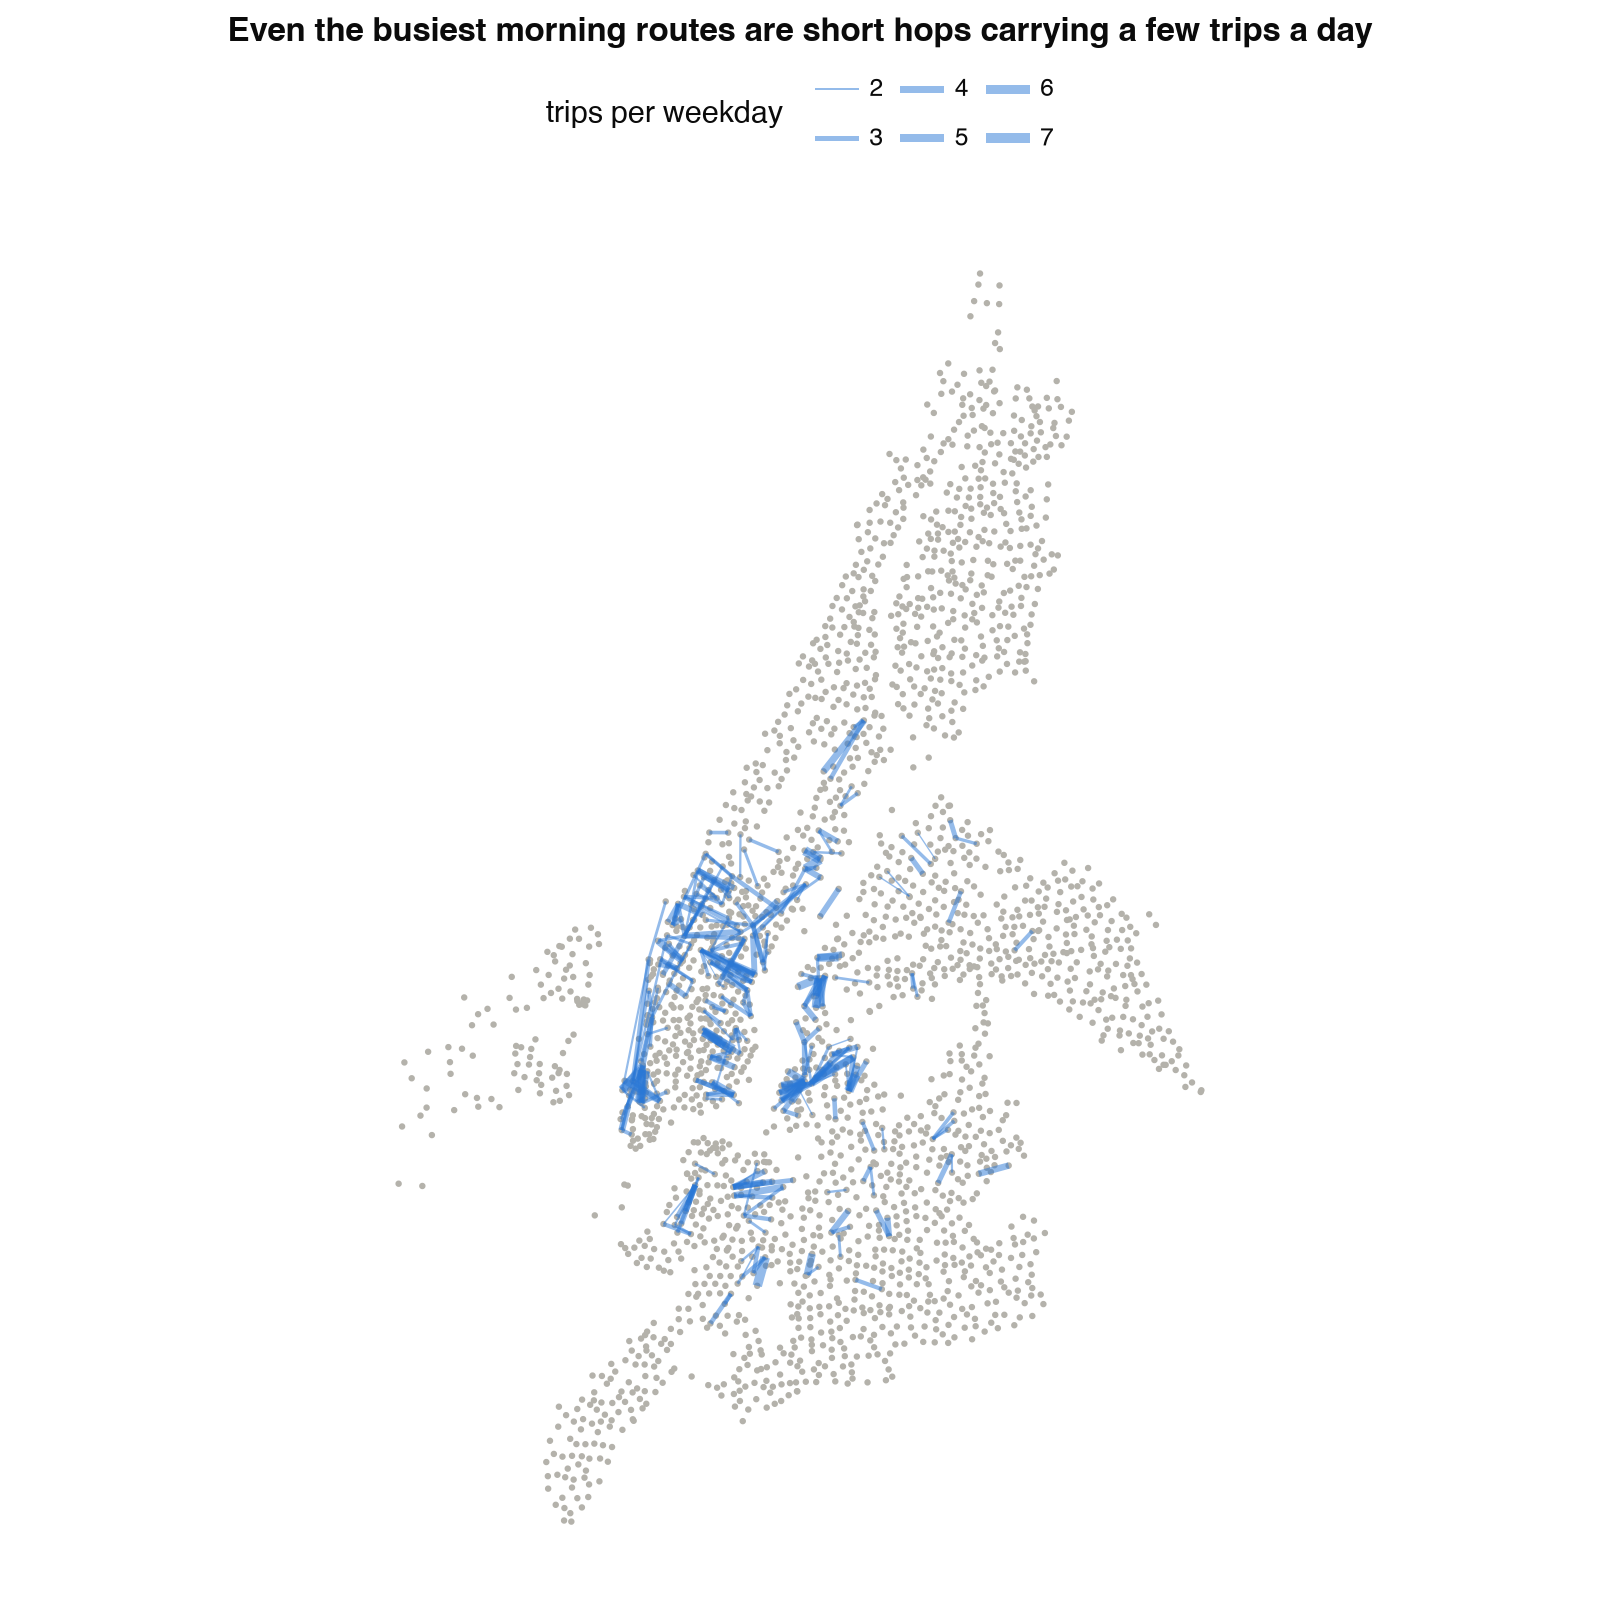

In [26]:

(
    ggplot()
    + geom_point(aes("lng", "lat"), data=stations, color=CONTEXT, size=0.3)
    + geom_segment(
        aes("lng", "lat", xend="lng_end", yend="lat_end", size="trips_per_day"),
        data=corridors.with_columns(trips_per_day=pl.col("trips") / weekdays_in_dev),
        color=BLUE,
        alpha=0.5,
    )
    + scale_size(range=(0.2, 2))
    + coord_fixed(ratio=LNG_PER_LAT)
    + labs(
        title="Even the busiest morning routes are short hops carrying a few trips a day",
        size="trips per weekday",
    )
    + MAP_THEME
    + theme(figure_size=(8, 8))
)

The 300 routes cluster in Midtown, along the Hudson, and in Long Island City, Greenpoint and Williamsburg, and almost all of them are short. Few cross a river.

### 3.8 Season and weather

Add up each `dev` day's trips, and mark the days with at least 5 mm of rain or snow.

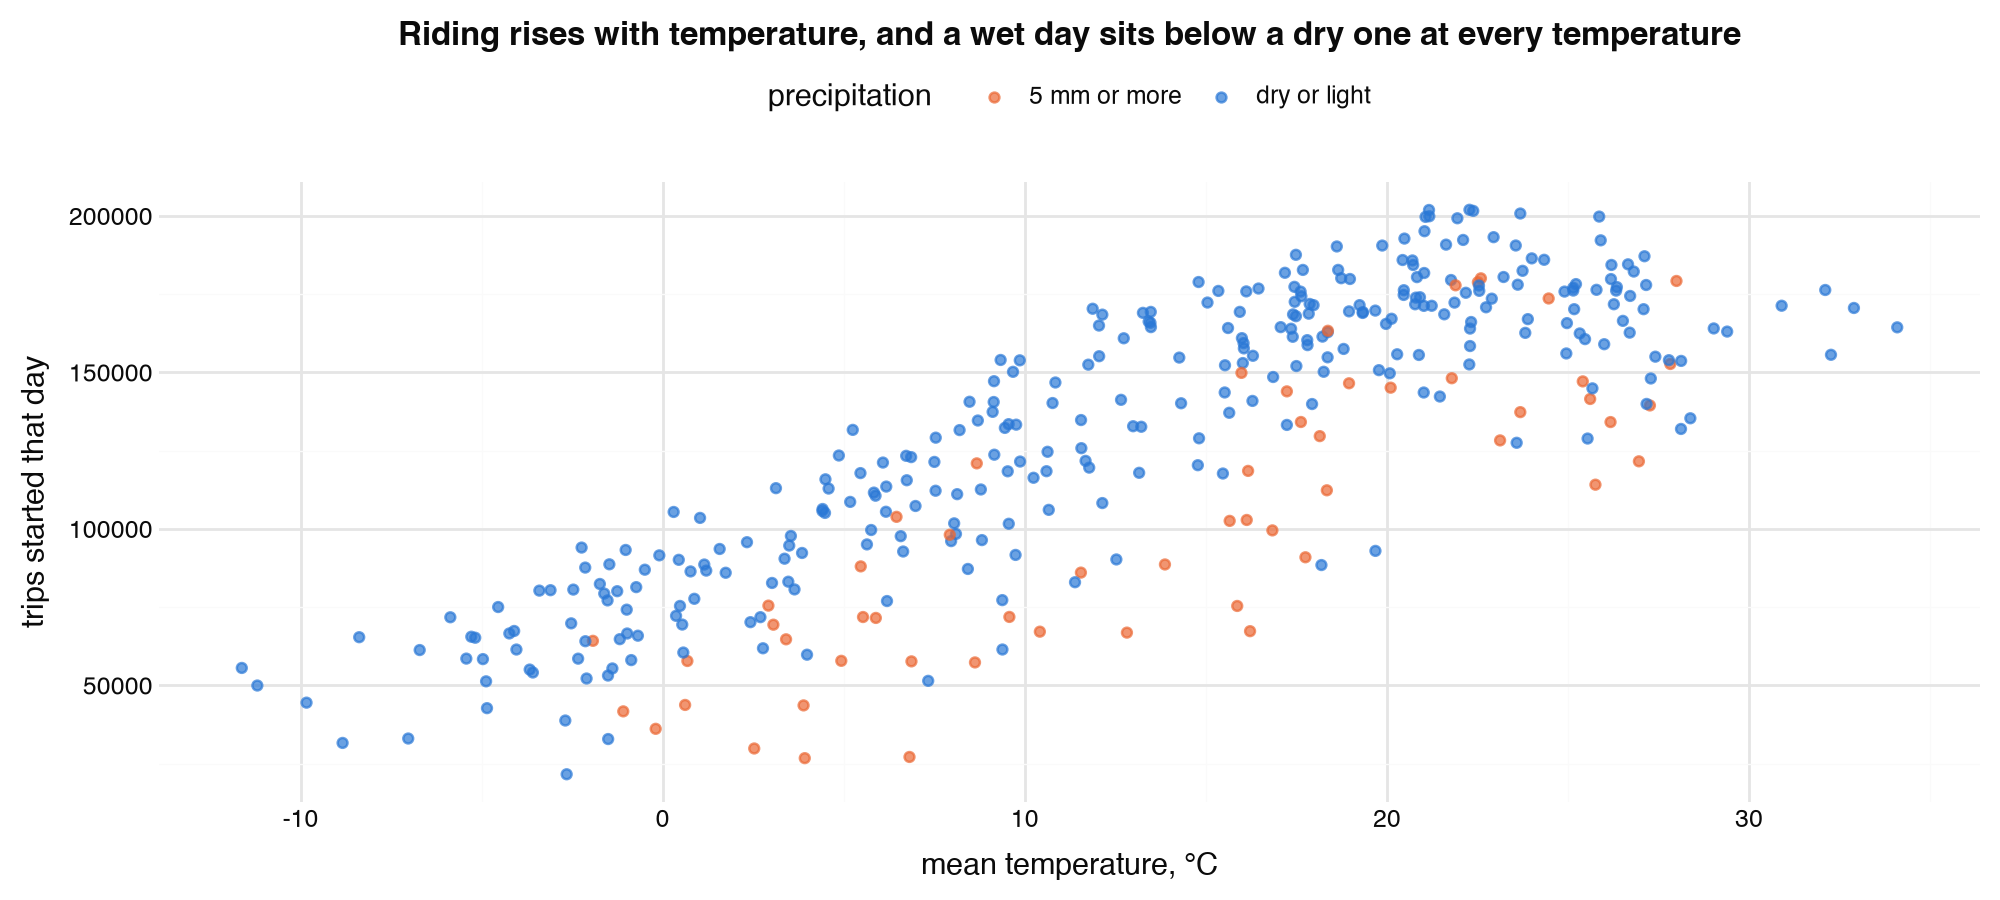

In [27]:
daily = (
    dev.group_by(date=pl.col("hour").dt.date())
    .agg(
        pl.col("starts").sum(),
        pl.col("net_flow").abs().sum().alias("imbalance"),
    )
    .join(
        weather.group_by(date=pl.col("hour").dt.date()).agg(
            pl.col("temperature_c").mean(), pl.col("precipitation_mm").sum()
        ),
        on="date",
    )
    .with_columns(
        wet=pl.when(pl.col("precipitation_mm") >= 5)
        .then(pl.lit("5 mm or more"))
        .otherwise(pl.lit("dry or light")),
    )
)

(
    ggplot(daily, aes("temperature_c", "starts", color="wet"))
    + geom_point(alpha=0.7)
    + scale_color_manual(values={"dry or light": BLUE, "5 mm or more": ORANGE})
    + labs(
        title="Riding rises with temperature, and a wet day sits below a dry one at every temperature",
        x="mean temperature, °C",
        y="trips started that day",
        color="precipitation",
    )
)

Daily trips rise from about 50,000 on the coldest days to about 175,000 at 20 °C to 25 °C, and level off above that. Wet days sit below dry days at every temperature.

Compare wet and dry days at the same temperature: group the days into 5 °C bands and divide the wet days' median trips by the dry days' in each band. `wet_to_dry_ratio` at 0.7 means a wet day brings 30% fewer riders than a dry day of the same warmth.

In [28]:
(
    daily.with_columns(
        temperature_band=(pl.col("temperature_c") // 5 * 5).cast(pl.Int32)
    )
    .group_by("temperature_band", "wet")
    .agg(pl.len().alias("days"), pl.col("starts").median())
    .pivot("wet", index="temperature_band", values=["days", "starts"])
    .with_columns(
        wet_to_dry_ratio=pl.col("starts_5 mm or more") / pl.col("starts_dry or light")
    )
    .sort("temperature_band")
)

temperature_band,days_5 mm or more,days_dry or light,starts_5 mm or more,starts_dry or light,wet_to_dry_ratio
i32,u32,u32,f64,f64,f64
-15,null,2,null,52723.500,null
-10,null,9,null,61250.000,null
-5,3,37,41657.000,66553.000,0.626
0,9,32,57752.000,89328.000,0.647
5,10,47,71817.000,113486.000,0.633
10,4,33,76558.500,140103.000,0.546
15,14,56,115394.500,164942.500,0.700
20,8,54,160845.000,175905.500,0.914
25,8,34,140439.500,170162.000,0.825


At the same temperature, a wet day brings 9% to 45% fewer riders than a dry one, and 30% to 45% fewer below 20 °C. Each band holds only 3 to 14 wet days, so these are rough sizes. Rain changes how many people ride, so it matters for a forecast of the day's volume.

`imbalance` is the sum over every station-hour of the day of `|net_flow|`: the bikes that would have to be moved to undo every hour's flow. Compare it with the day's trips, to see whether a busy day is also a more lopsided one.

In [29]:
daily.select(
    pl.corr("starts", "imbalance").alias("correlation"),
    (pl.col("imbalance") / pl.col("starts"))
    .median()
    .alias("imbalance_per_trip_median"),
)

correlation,imbalance_per_trip_median
f64,f64
0.971,0.560


A day's imbalance tracks its trips at a correlation of 0.97, at about 0.56 bikes of hourly imbalance per trip. A busy day is a bigger version of an ordinary day, not a more lopsided one, so the amount of rebalancing can scale with the demand expected.

### What the exploration found

Ranked by how much each finding should change the schedule:

1. The imbalance is a habit of each station. A station's average morning flow in one half of the weeks matches the other half at a correlation of 0.998, so a schedule built from past weeks fits the weeks after. The pattern sits at the level of station, hour and day type.
2. The overnight level decides most days. Reset to half full, a station runs empty or full on 20.5% of weekdays, but on only 1.1% would no starting level have worked. A better overnight level would have avoided 95% of the short days; bikes moved during the day matter mainly for the nine stations that swing by more than their docks on a typical weekday.
3. Weekdays and weekends are different problems. Weekday members create two sharp rush peaks that move bikes in one direction, while weekends follow one midday curve, and each needs its own profile.
4. Weather and season change the volume, not the shape. Trips rise with temperature and a wet day brings 9% to 45% fewer riders, but a day's imbalance scales with its trips (correlation 0.97), so weather enters as a volume adjustment.
5. The flow is spread over thousands of small routes. Together the 300 busiest carry 3.6% of morning-rush trips, which is why the schedule targets stations, not routes.

To keep in mind: the shortage shares in finding 2 are lower bounds, since hourly totals hide swings inside an hour and riders who found a station empty left no record. 4.1% of trip ends are at stations without a dock count. A few stations lose or gain over 100 bikes in an hour, most likely through valet staff, and 23 February 2026 in the test year has no trips. Every number here comes from `dev`, October 2024 to September 2025.